# 极客项目 ch04：Karplus-Strong 算法生成音乐

对应《Python Playground》第 4 章（Karplus-Strong）。WAV 写入系统临时目录，图形为波形演示；**pygame 播放部分保留代码但不执行**（本机无 pygame）。

In [1]:
# ===== 公共设置 =====
%matplotlib inline
import os
import wave
import random
import tempfile
import numpy as np
from collections import deque
import matplotlib.pyplot as plt

random.seed(2027)
np.random.seed(2027)
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False

# 五声音阶 C4-Eb-F-G-Bb
pmNotes = {'C4': 262, 'Eb': 311, 'F': 349, 'G': 391, 'Bb': 466}

## 书 4.3.1 deque 环形缓冲区

`append` / `popleft` 都是 O(1)，天然匹配 Karplus-Strong 每步"删头加尾"的滚动。

In [2]:
# ===== 书 4.3.1 节 deque 演示 =====
d = deque(range(10))
print(d)
d.append(-1)
print(d)
print(d.popleft())
print(d)

deque([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
deque([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, -1])
0
deque([1, 2, 3, 4, 5, 6, 7, 8, 9, -1])


## 书 4.3.2 Karplus-Strong 算法

环形缓冲长度 $N = S/f$ 决定基频；每步输出头部样本、把"衰减平均"塞回尾部——随机噪声沉淀成周期波。`gShowPlot` 交互开关保留原文（`--display` 模式用）。

In [3]:
# ===== 书 4.3.2 节 generateNote() =====
# show plot of algorithm in action?
gShowPlot = False

def generateNote(freq):
    nSamples = 44100
    sampleRate = 44100
    N = int(sampleRate/freq)  # 环形缓冲长度 = 一个周期
    buf = deque([random.random() - 0.5 for i in range(N)])
    if gShowPlot:
        axline, = plt.plot(buf)
    samples = np.array([0]*nSamples, 'float32')
    for i in range(nSamples):
        samples[i] = buf[0]
        avg = 0.995*0.5*(buf[0] + buf[1])  # 衰减平均
        buf.append(avg)
        buf.popleft()
        if gShowPlot:
            if i % 1000 == 0:
                axline.set_ydata(buf)
                plt.draw()
    # 16-bit PCM
    samples = np.array(samples * 32767, 'int16')
    return samples.tobytes()  # Py3：tostring()→tobytes()


## 书 4.3.3 写 WAV 文件

单声道、16 位、44100 Hz、无压缩；`generateNote` 返回的 bytes 直接 `writeframes`。

In [4]:
# ===== 书 4.3.3 节 writeWAVE() =====
def writeWAVE(fname, data):
    file = wave.open(fname, 'wb')
    nChannels = 1
    sampleWidth = 2
    frameRate = 44100
    nFrames = 44100
    file.setparams((nChannels, sampleWidth, frameRate, nFrames,
                    'NONE', 'noncompressed'))
    file.writeframes(data)
    file.close()


## 书 4.3.4–4.3.5 pygame 播放（不执行）

> 本机无 pygame（`pip install pygame` 后可用 --display/--play/--piano）；`NotePlayer` 与 main() 的播放逻辑保留代码但不执行。

In [ ]:
# ===== 书 4.3.4 节 NotePlayer（不执行：需 pygame）=====
# play a wav file
class NotePlayer:
    def __init__(self):
        pygame.mixer.pre_init(44100, -16, 1, 2048)
        pygame.init()
        self.notes = {}

    def add(self, fileName):
        self.notes[fileName] = pygame.mixer.Sound(fileName)

    def play(self, fileName):
        try:
            self.notes[fileName].play()
        except KeyError:
            print(fileName + ' not found!')

    def playRandom(self):
        """play a random note"""
        index = random.randint(0, len(self.notes)-1)
        note = list(self.notes.values())[index]
        note.play()


In [ ]:
# ===== 书 4.3.5 节 main()（argparse 略；不执行：需 pygame + 音频设备）=====
import sys
import time

try:
    import pygame
except ImportError:
    pygame = None  # pip install pygame 后可用 --display/--play/--piano

def main(args):
    global gShowPlot

    if (args.display or args.play or args.piano) and pygame is None:
        sys.exit('需要 pygame：pip install pygame 后可用 --display/--play/--piano')

    # --display：边生成边画缓冲区（gShowPlot 交互刷新）
    if args.display:
        gShowPlot = True
        plt.ion()

    nplayer = NotePlayer() if pygame is not None else None

    print('creating notes...')
    for name, freq in list(pmNotes.items()):
        fileName = name + '.wav'
        if not os.path.exists(fileName) or args.display:
            data = generateNote(freq)
            print('creating ' + fileName + '...')
            writeWAVE(fileName, data)
        else:
            print('fileName already created. skipping...')

        if nplayer is not None:
            nplayer.add(name + '.wav')

        if args.display:
            nplayer.play(name + '.wav')
            time.sleep(0.5)

    # --play 模式：随机播放
    if args.play:
        while True:
            try:
                nplayer.playRandom()
                # rest - 1 to 8 beats
                rest = np.random.choice([1, 2, 4, 8], 1,
                                        p=[0.15, 0.7, 0.1, 0.05])
                time.sleep(0.25*rest[0])
            except KeyboardInterrupt:
                exit()

    # --piano 模式：按键随机发声
    if args.piano:
        while True:
            for event in pygame.event.get():
                if (event.type == pygame.KEYUP):
                    print("key pressed")
                    nplayer.playRandom()
                    time.sleep(0.5)

## 演示：固定种子生成五声音阶

五个音符各生成 1 秒（44100 样本），WAV 写入临时目录；画每个音符前 8000 个样本的波形——同一把"拨弦"（seed=2027），不同 N 对应不同音高。

C4: f=262 Hz, N=168, 实际基频=262.5 Hz
Eb: f=311 Hz, N=141, 实际基频=312.8 Hz
F: f=349 Hz, N=126, 实际基频=350.0 Hz
G: f=391 Hz, N=112, 实际基频=393.8 Hz
Bb: f=466 Hz, N=94, 实际基频=469.1 Hz


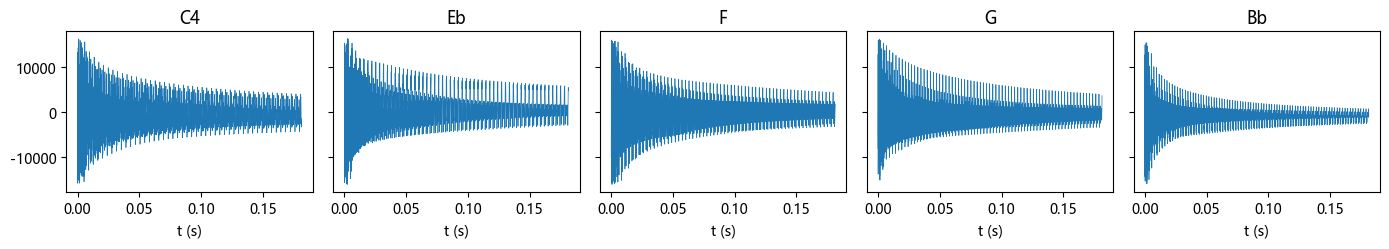

In [5]:
# ===== 演示：五声音阶生成（WAV 写临时目录 + 波形图）=====
random.seed(2027)                      # 每个音符的拨弦初始噪声可复现
out_dir = tempfile.mkdtemp(prefix='pg_ch04_')

notes = {}
for name, freq in pmNotes.items():
    data = generateNote(freq)          # 16-bit PCM 字节串
    fname = os.path.join(out_dir, name + '.wav')
    writeWAVE(fname, data)
    notes[name] = np.frombuffer(data, dtype=np.int16)
    N = int(44100/freq)
    print('%s: f=%d Hz, N=%d, 实际基频=%.1f Hz' % (name, freq, N, 44100/N))

fig, axes = plt.subplots(1, 5, figsize=(14, 2.6), sharey=True)
t = np.arange(8000)/44100.0
for axi, (name, smp) in zip(axes, notes.items()):
    axi.plot(t, smp[:8000], lw=0.5)
    axi.set_title(name)
    axi.set_xlabel('t (s)')
plt.tight_layout()
plt.show()